In [3]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import shuffle
from sklearn.preprocessing import LabelEncoder


import tensorflow as tf

RANDOM_KEY=26
TAILLE_IMAGE=(224, 224)
BATCH_SIZE = 32

 # Charger les images

In [4]:
def charger_images(path: str):
    images = []
    labels = []

    extensions_valides = {".jpeg", ".jpg", ".bmp", ".png"}

    for folder in Path(path).iterdir():
        if not folder.is_dir():
            continue
        label = folder.name
        for file in folder.iterdir():
            if file.suffix.lower() not in extensions_valides:
                continue

            try:
                image = cv2.imread(str(file))
                if image is None:
                    raise OSError(f"Image illisible : {file}")

                image = cv2.resize(image, TAILLE_IMAGE)
                images.append(image)
                labels.append(label)
            except (cv2.error, OSError, ValueError) as erreur:
                print(f"Erreur : {fichier} — {erreur}")
    return images, labels

images, labels = charger_images('/kaggle/input/datasets/hamzahajjaji/dataset-brief-5/Data')

print("Nomber d'images :", len(images))
print("Nomber de labels :", len(labels))

print('Shape de 1 image:', images[0].shape)
print('Labels de 1 image:', labels[0])

Nomber d'images : 7023
Nomber de labels : 7023
Shape de 1 image: (224, 224, 3)
Labels de 1 image: glioma


# Convertir les listes en tableaux NumPy

In [5]:
def convertir_numpy():
    return np.array(images, dtype=np.float32), np.array(labels)

X, y = convertir_numpy()

print("Shape de X :", X.shape)
print("Shape de y :", y.shape)

print("Type de X :", type(X))
print("Type de y :", type(y))

print("Premier label :", y[0])

Shape de X : (7023, 224, 224, 3)
Shape de y : (7023,)
Type de X : <class 'numpy.ndarray'>
Type de y : <class 'numpy.ndarray'>
Premier label : glioma


# Normaliser les images

In [6]:
def normaliser_images():
    return X / 255

X_normalized = normaliser_images()

print("Shape :", X_normalized.shape)
print("Type :", X_normalized.dtype)
print("Pixel minimum :", X_normalized.min())
print("Pixel maximum :", X_normalized.max())

Shape : (7023, 224, 224, 3)
Type : float32
Pixel minimum : 0.0
Pixel maximum : 1.0


# Encoder les labels avec LabelEncoder

In [7]:
def encoder_labels():
    encoder = LabelEncoder()
    y_encoded = encoder.fit_transform(y)
    return y_encoded, encoder

y_encoded, label_encoder = encoder_labels()

print("Classes :", label_encoder.classes_)
print("Labels originaux :", y[:5])
print("Labels encodés :", y_encoded[:5])

Classes : ['glioma' 'meningioma' 'notumor' 'pituitary']
Labels originaux : ['glioma' 'glioma' 'glioma' 'glioma' 'glioma']
Labels encodés : [0 0 0 0 0]


# Afficher un échantillon d'images

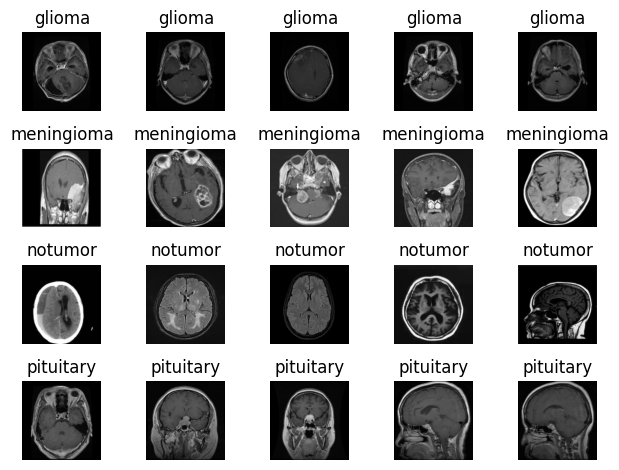

In [8]:
def afficher_exemples():
    classes = np.unique(y)

    _, axes = plt.subplots(len(classes), 5)

    for i, classe in enumerate(classes):
        indexes = np.where(y == classe)[0][:5] # index 0 parce que where  return tupe aec 2 values
        
        for j, index in enumerate(indexes):
            image = cv2.cvtColor(X_normalized[index], cv2.COLOR_BGR2RGB)
            axes[i, j].imshow(image)
            axes[i, j].set_title(str(classe))
            axes[i, j].axis("off")
            
    plt.tight_layout()
    plt.show()

afficher_exemples()

# Afficher la distribution et l'équilibre des images

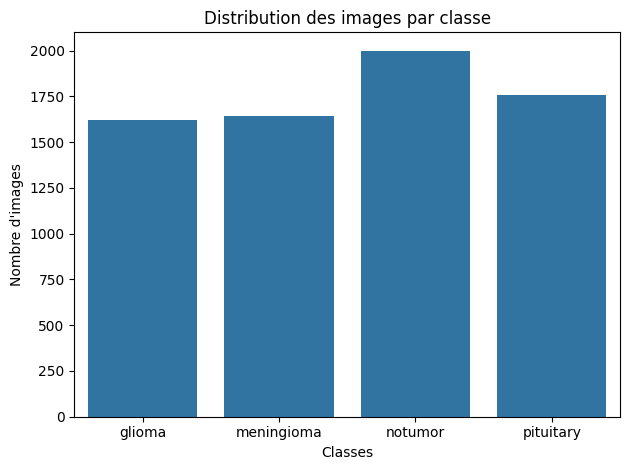

In [9]:
def afficher_distribution():
    classes, counts = np.unique(y, return_counts=True)
    plt.figure()

    sns.barplot(
        x=classes,
        y=counts
    )

    plt.title("Distribution des images par classe")
    plt.xlabel("Classes")
    plt.ylabel("Nombre d'images")
    plt.tight_layout()
    plt.show()

afficher_distribution()

# Encapsuler le chargement dans un module

In [11]:
train_ds = tf.data.Dataset.from_tensor_slices((X_normalized, y_encoded))

# Mélanger les images
train_ds = train_ds.shuffle(
    buffer_size=len(X_normalized), # pour utiliser tout les donnes dasn mélange
    seed=RANDOM_KEY
)

# Regrouper les images
train_ds = train_ds.batch(BATCH_SIZE)

# Accélérer le chargement avec prefetch
train_ds = train_ds.prefetch(
    buffer_size=tf.data.AUTOTUNE
)


for images, labels in train_ds.take(1):
    print("Images :", images.shape)
    print("Labels :", labels.shape)

Images : (32, 224, 224, 3)
Labels : (32,)
